# Covariance comparisons using the complete measured samples

**Thanks to Rafael Gomes for the maps and released analysis products, to
Oliver Friedrich and Tim Eifler for the precision-matrix expansion, and to
Mike Jarvis and the TreeCorr contributors for the pair measurements.**
This notebook accompanies [the comparison note](covariance_comparison.pdf).
It contains exactly two scientific comparisons:

1. Direct covariance from **all 15,997 measured aperture vectors**, versus
   the second-, fourth- and sixth-order Eifler precisions converted to covariances, using
   that same full sample and the fixed starting matrix.
2. Our existing four-bin xi-plus covariance versus the released DES joint
   covariance. All 32 currently measured primary xi-plus vectors enter that
   comparison. This second measurement has not been run on all 15,997 maps.

There is no calibration/correction/validation partition in these comparisons.
They compare estimators and processing choices on shared data; neither is an
independent validation experiment.

Run from this notebook's folder in the normal Cocoa checkout. Small recorded
matrices and vectors in `tests/covariance_map_comparison/` reproduce every
plot without the map archive. Shared statistics and plots come from
`cosmolike_core`; no compiled interface or cosmological model is run.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
from pathlib import Path
import subprocess
import sys

# One worker suffices for the small matrix calculations. The optional pair
# driver explicitly sets OpenMP to three, leaving BLAS at one.
for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from astropy.io import fits
from threadpoolctl import threadpool_limits
blas_limit = threadpool_limits(limits=1, user_api="blas")
NOTE = Path.cwd()
PROJECT = NOTE.parents[1]
if not (NOTE / "covariance_comparison.tex").is_file():
    raise ValueError("Use notes/covariance_comparison as the working directory.")
MEASUREMENT = PROJECT / "tests" / "covariance_map_comparison"
RUN_MEASUREMENT = False
RECOMPUTE_ALL_COVARIANCE = False

# This switch runs the existing, documented project driver. No new model,
# cosmology provider, or notebook-specific likelihood is constructed.
if RUN_MEASUREMENT:
    subprocess.run(
        args=[sys.executable, str(PROJECT / "scripts" / "measure_covariance_xip.py"),
              "--runs", "32"],
        cwd=PROJECT,
        check=True,
    )
    MEASUREMENT = PROJECT / "chains" / "covariance_xip_comparison"
print("Measurement source:", MEASUREMENT)
CORE = PROJECT.parents[1] / "external_modules" / "code" / "cosmolike_core"
sys.path.insert(0, str(CORE))
from cosmolike_notebook_utils.covariance import precision as cp
from cosmolike_notebook_utils import plot_covariances as covplots


Measurement source: /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/tests/covariance_map_comparison


In [2]:
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

## 1. Use every measured aperture vector in both methods

Each of the 15,997 files contributes the same 16 rows: eight raw squared
aperture moments and eight raw cubed moments. Each block orders four source
slots and two radii (30, 60 arcmin) within each source. The same 64 centers
are used throughout. These are the coarse diagnostic moments, **not** the
published xi/finite-triangle Map3 vector.

Let $d_s$ be the vector from file $s$. First subtract the sample mean:

$$e_s=d_s-\bar d.$$

The direct simulation covariance is

$$C_{\rm sim}=\frac{1}{N-1}\sum_{s=1}^N e_s e_s^{\mathsf T}.$$

This describes fluctuations of one vector. We do not divide it again by
$N$, which would change it into a covariance of the ensemble mean.
The Eifler calculation below receives **this same matrix**. There is no
held-out group and no new fit of the reference matrix.

In [3]:
# The small input matrix is the covariance of every saved aperture vector.
# To recompute it from the local measured-vector table, enable the switch
# above. This reads a small text table, not the simulation maps themselves.
all_folder = PROJECT / "tests" / "covariance_map_comparison"
all_covariance = np.loadtxt(fname=all_folder / "all_maps_covariance.txt")
all_reference = np.loadtxt(fname=all_folder / "aperture_reference.txt")
all_count = 15997
if RECOMPUTE_ALL_COVARIANCE:
    records = np.loadtxt(
        fname=PROJECT / "chains" / "covariance_maps_full" / "moments.txt",
    )
    vectors = records[:, 3:]
    residuals = vectors - np.mean(a=vectors, axis=0)
    recomputed = residuals.T @ residuals / (len(vectors) - 1)
    np.testing.assert_allclose(recomputed, all_covariance, rtol=1.e-12, atol=1.e-30)
    all_covariance = recomputed
    all_count = len(vectors)
assert all_covariance.shape == (16, 16)
print("File count used by BOTH methods:", all_count)
print("Direct sample covariance is positive definite:",
      np.all(np.linalg.eigvalsh(all_covariance) > 0.))
# Diagonal entries have different units for squared and cubed moments.
# Cholesky transformations below make comparisons dimensionless.
all_factor = np.linalg.cholesky(all_reference)
all_whitened = cp.whiten_covariance(covariance=all_covariance, factor=all_factor)


File count used by BOTH methods: 15997
Direct sample covariance is positive definite: True


## 2. Compute the second-order Eifler estimate

Write the fixed starting covariance as $M=LL^{\mathsf T}$. Express the
simulation covariance in its units:

$$S=L^{-1}C_{\rm sim}L^{-\mathsf T}.$$

For independent Gaussian summary vectors, the Wishart expression for an
unbiased estimate of the **matrix square** of the mean of $S$ is

$$Q=\frac{\nu^2 S^2-\nu S\,\operatorname{tr}(S)}{\nu^2+\nu-2}.$$

The second-order polynomial is then

$$P_2=3I-3S+Q.$$

Restore the original precision units:

$$\Psi_{\rm E}=L^{-\mathsf T}P_2L^{-1}.$$

Eifler estimates a precision, the inverse covariance. To compare covariance
matrices, we check positivity and then calculate

$$C_{\rm E}=\Psi_{\rm E}^{-1}.$$

**Count convention for this requested all-file comparison:** the formula is
evaluated with nominal $\nu=15996$. Related files are not established to be
independent, nor are these nonlinear moments established to be Gaussian.
Thus the finite-$N$ term is a stated algebraic choice, not a validated
unbiased correction for this archive. No effective independent count is
inferred from the filenames. The reference remains fixed throughout.

In [4]:
# Work through the noisy-square arithmetic explicitly. Matrix multiplication
# S @ S is different from squaring each entry of S separately.
nu_nominal = all_count - 1.
all_square = all_whitened @ all_whitened
all_trace_product = all_whitened * np.trace(a=all_whitened)
all_quadratic = (nu_nominal**2 * all_square - nu_nominal * all_trace_product)
all_quadratic /= nu_nominal**2 + nu_nominal - 2.
all_polynomial = 3. * np.eye(16) - 3. * all_whitened + all_quadratic
minimum_polynomial = np.linalg.eigvalsh(all_polynomial)[0]
assert minimum_polynomial > 0.

# Use the existing shared routine for the original-unit result. Its count
# argument evaluates the same nominal formula; this numerical check does not
# establish the archive's independent-simulation count.
all_precision, all_diagnostics = cp.precision_expansion(
    analytic=all_reference,
    sample=all_covariance,
    independent_count=all_count,
    order=2,
)
np.testing.assert_allclose(
    all_factor.T @ all_precision @ all_factor,
    all_polynomial,
    rtol=1.e-12,
    atol=1.e-14,
)
all_eifler_covariance = np.linalg.solve(a=all_precision, b=np.eye(16))
all_direct_precision = np.linalg.solve(a=all_covariance, b=np.eye(16))
print("Minimum dimensionless Eifler precision eigenvalue:", minimum_polynomial)
print("Estimated expansion radius:", all_diagnostics["estimated_residual_spectral_radius"])
all_sigma_ratio = np.sqrt(np.diag(all_eifler_covariance) / np.diag(all_covariance))
print("Change in per-row standard deviation [%]:", 100. * (all_sigma_ratio - 1.))
all_correlation = all_covariance / np.sqrt(
    np.outer(np.diag(all_covariance), np.diag(all_covariance)),
)
eifler_correlation = all_eifler_covariance / np.sqrt(
    np.outer(np.diag(all_eifler_covariance), np.diag(all_eifler_covariance)),
)
print("Maximum absolute correlation change:",
      np.max(a=np.abs(eifler_correlation - all_correlation)))
# These traces are comparisons on the SAME sample, not validation scores.
print("Direct inverse times its own sample covariance, trace/16:",
      np.trace(a=all_direct_precision @ all_covariance) / 16.)
print("Eifler precision times that sample covariance, trace/16:",
      np.trace(a=all_precision @ all_covariance) / 16.)


Minimum dimensionless Eifler precision eigenvalue: 0.820421269668298
Estimated expansion radius: 0.8320541113550121
Change in per-row standard deviation [%]: [11.46427786 11.42002847 12.35351112 11.11038032 12.53436572 11.98107479
 12.05239398 10.77206533  0.21872942  0.88940865  1.4427923   0.18903645
  0.73038933  0.09629184  0.84681884 -0.12044178]
Maximum absolute correlation change: 0.1990633284179183
Direct inverse times its own sample covariance, trace/16: 1.0
Eifler precision times that sample covariance, trace/16: 0.9583450897529554


## 3. Read the covariance-difference and split-triangle plots

The difference plot uses the direct simulation standard deviations to
normalize every entry:

$$\Delta_{ij}=100\,
\frac{(C_{\rm E}-C_{\rm sim})_{ij}}
 {\sqrt{(C_{\rm sim})_{ii}(C_{\rm sim})_{jj}}}.$$

On the diagonal this is the percentage change in **variance**, not standard
deviation. Off the diagonal it remains finite even when a reference
covariance entry is close to zero. The histogram includes all matrix entries,
including symmetric duplicates; its bars are not independent observations.

The triangle plot instead normalizes each method by its own diagonal to
show correlation coefficients. With the plotting function's upward row
axis, Eifler occupies the **upper-left** displayed triangle and direct
simulations the **lower-right**. No matrix entry is changed or clipped.

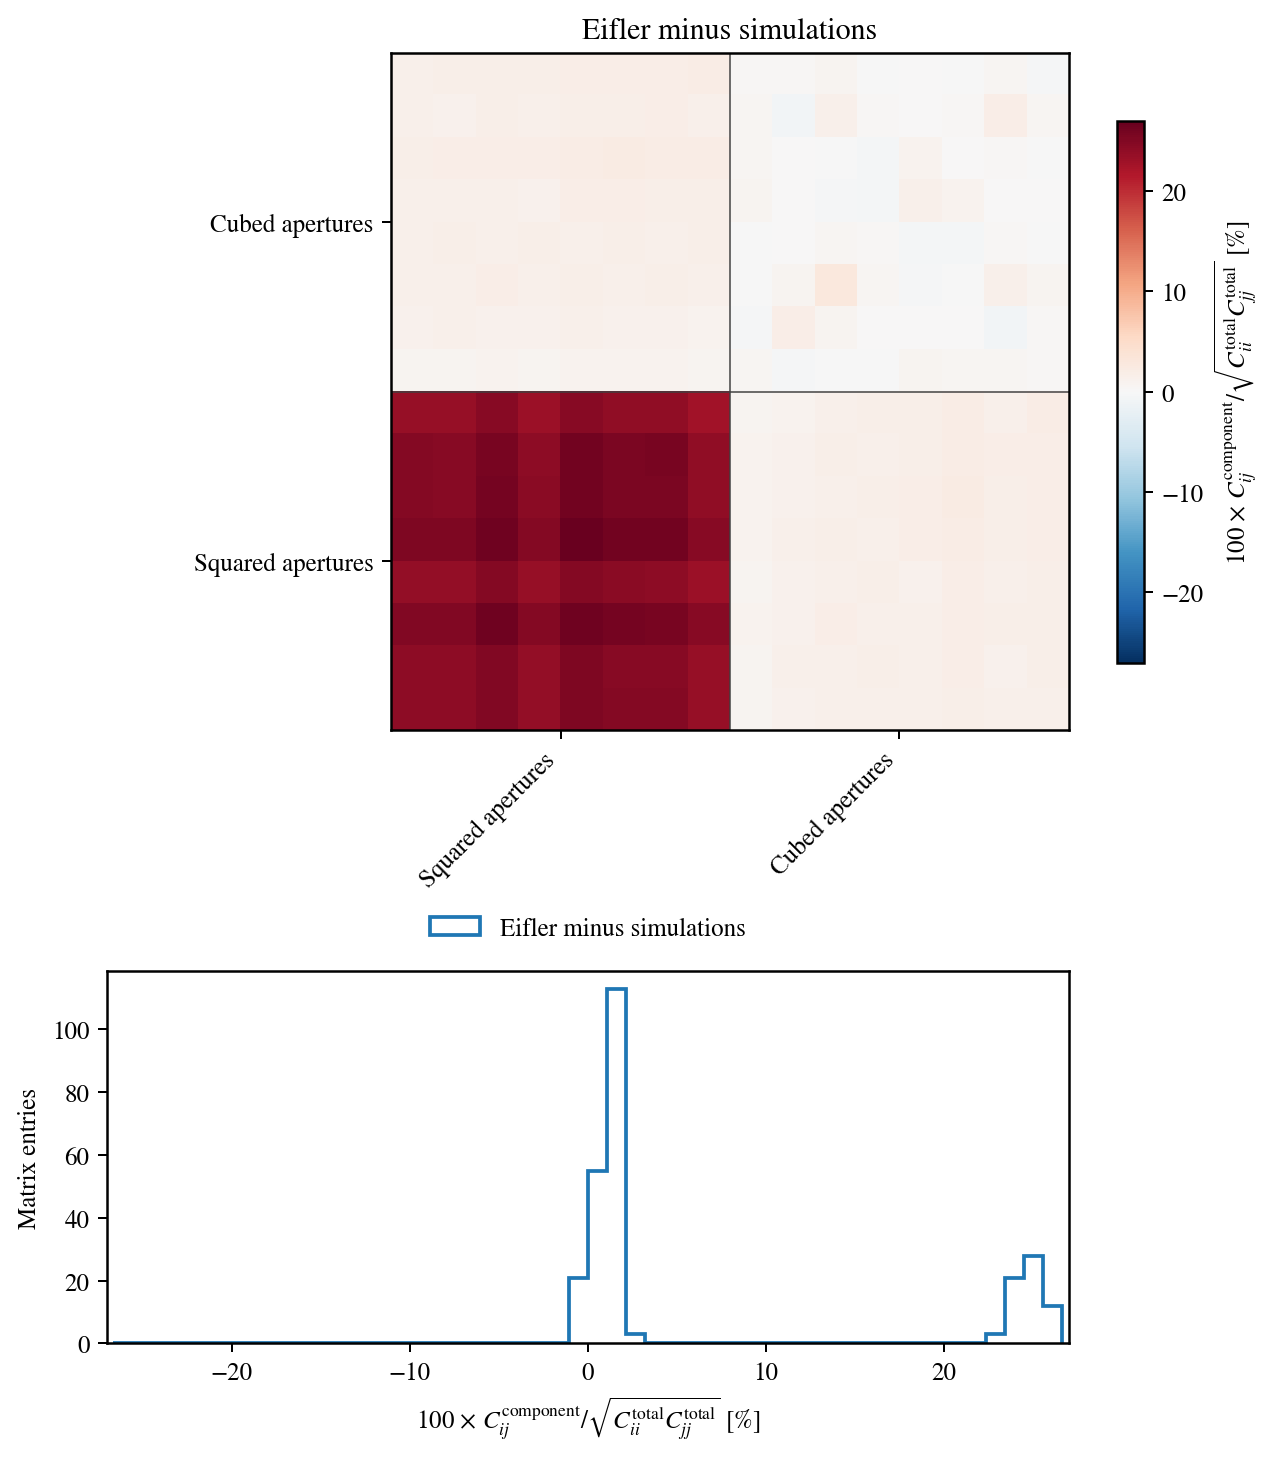

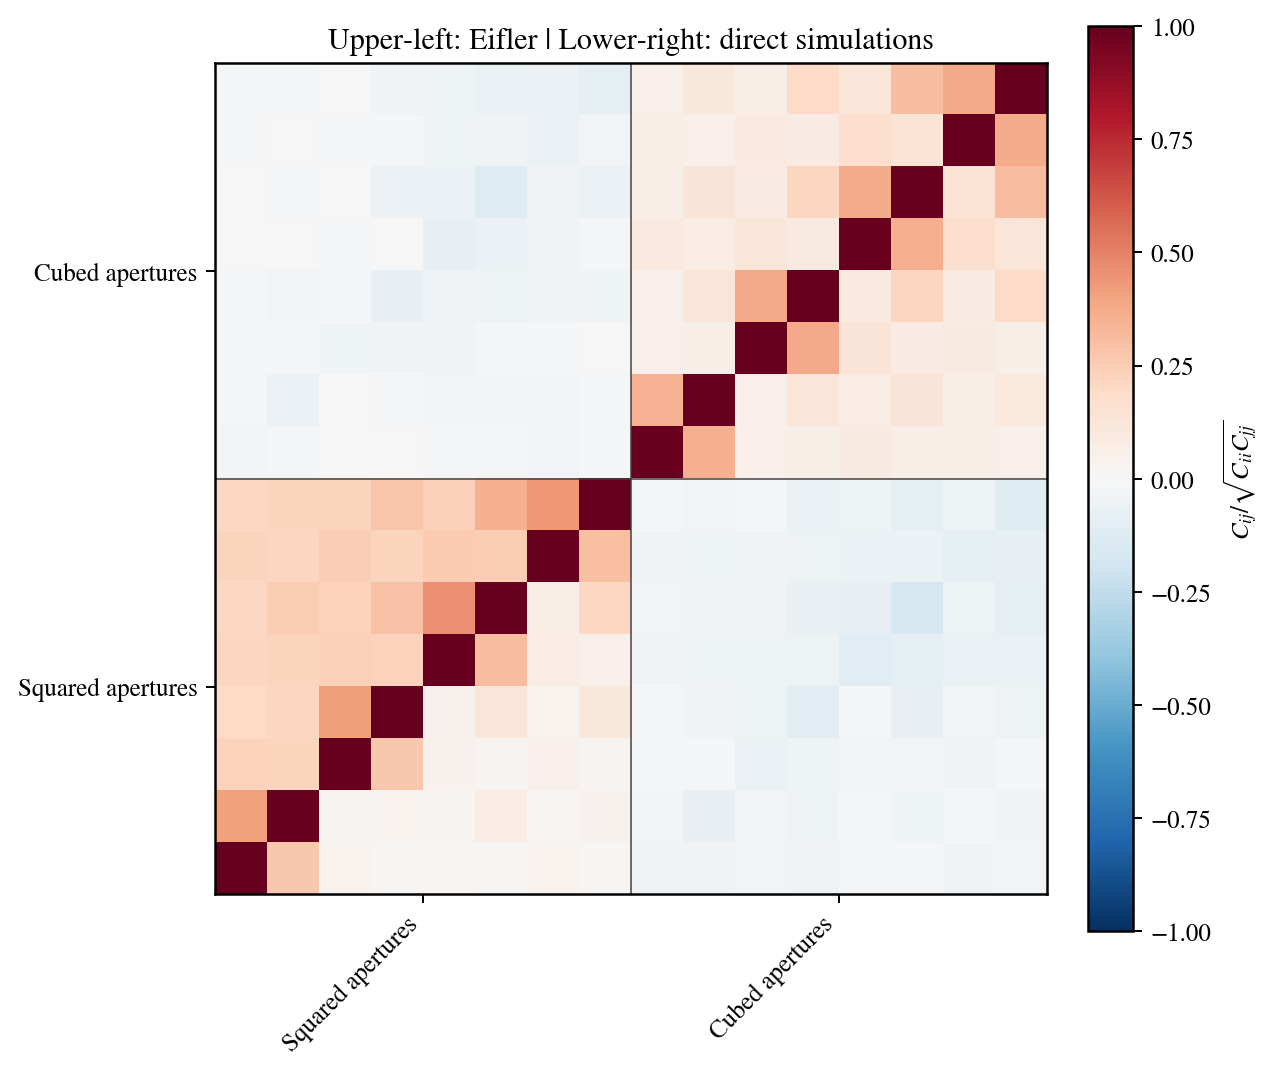

In [5]:
fig, axes = covplots.plot_covariance_components(
    total=all_covariance,
    components={"Eifler minus simulations": all_eifler_covariance - all_covariance},
    block_sizes=[8, 8],
    block_labels=["Squared apertures", "Cubed apertures"],
    normalization="diagonal",
    percent=True,
    figsize=(7, 8),
    show=None,
)
axes["maps"][0].set_title(label="Eifler minus simulations")
# Use the same color range for second and fourth order.
axes["maps"][0].images[0].set_clim(vmin=-27., vmax=27.)
axes["histogram"].set_xlim(left=-27., right=27.)
fig.canvas.draw()
legend = axes["histogram"].get_legend()
assert legend.get_window_extent().y0 > axes["histogram"].get_window_extent().y1
plt.show()

fig, ax = covplots.plot_correlation(
    covariance=all_eifler_covariance,
    covariance_ref=all_covariance,
    block_sizes=[8, 8],
    block_labels=["Squared apertures", "Cubed apertures"],
    labels=["Eifler", "Direct simulations"],
    figsize=(7, 6),
    show=None,
)
ax.set_title(label="Upper-left: Eifler | Lower-right: direct simulations")
plt.show()

### Fourth order, using the same complete sample

Apply the cubic and quartic **Wishart noise corrections**, using the same
nominal count and fixed reference as at second order. The full derivation
and Gaussian/lognormal tests are in our [Eifler teaching notes](../covariance_from_simulations/covariance_from_simulations.pdf)
and [teaching notebook](../../EXAMPLE_COVARIANCE_PME.ipynb).
Here we record only the computation and its comparison with the direct
simulation covariance. Related files and the reference provenance still
prevent a claim of established unbiasedness for this archive.
The following code keeps each matrix/trace term visible for reproduction.


In [6]:
# These coefficients follow the exact Gaussian moment derivation in the
# teaching note. This calculation does not assert Gaussian/independent maps.
nu = float(all_count - 1)
cube = all_square @ all_whitened
fourth = all_square @ all_square
trace1 = np.trace(a=all_whitened)
trace2 = np.trace(a=all_square)
trace3 = np.trace(a=cube)
denominator3 = (nu - 2) * (nu - 1) * (nu + 2) * (nu + 4)
q3 = nu**2 / denominator3 * (
    nu**2 * cube - 2 * nu * all_square * trace1
    - nu * all_whitened * trace2 + 2 * all_whitened * trace1**2
)
denominator4 = (
    (nu - 3) * (nu - 2) * (nu - 1) * (nu + 1)
    * (nu + 2) * (nu + 4) * (nu + 6)
)
coefficient_a = nu**2 + nu + 2
coefficient_b = 5 * nu + 6
q4 = nu**3 / denominator4 * (
    nu**2 * coefficient_a * fourth
    - 3 * nu * coefficient_a * cube * trace1
    - nu * (2 * nu**2 + 3 * nu - 6) * all_square * trace2
    + nu * coefficient_b * all_square * trace1**2
    - nu * coefficient_a * all_whitened * trace3
    + nu * coefficient_b * all_whitened * trace2 * trace1
    - coefficient_b * all_whitened * trace1**3
)
fourth_polynomial = (
    5 * np.eye(16) - 10 * all_whitened + 10 * all_quadratic - 5 * q3 + q4
)
assert np.min(np.linalg.eigvalsh(fourth_polynomial)) > 0.
# Transform back on both sides, then invert the positive precision to show
# its corresponding covariance. No eigenvalue clipping or fitted scaling.
fourth_left = np.linalg.solve(a=all_factor.T, b=fourth_polynomial)
fourth_precision = np.linalg.solve(a=all_factor.T, b=fourth_left.T).T
fourth_covariance = np.linalg.solve(a=fourth_precision, b=np.eye(16))
# Test in diagonal standard-deviation units: relative error against an
# almost-zero covariance entry would magnify harmless solve-rounding errors.
recorded_fourth = np.loadtxt(
    fname=NOTE / "plots" / "fourth_difference" / "first.txt",
)
comparison_scale = np.sqrt(np.outer(np.diag(all_covariance), np.diag(all_covariance)))
np.testing.assert_allclose(
    fourth_covariance / comparison_scale,
    recorded_fourth / comparison_scale,
    rtol=1.e-12,
    atol=1.e-13,
)
print("Fourth-order minimum dimensionless precision eigenvalue:",
      np.min(np.linalg.eigvalsh(fourth_polynomial)))
fourth_change = 100. * (
    np.sqrt(np.diag(fourth_covariance) / np.diag(all_covariance)) - 1.
)
print("Fourth-order standard-deviation changes [%]:", fourth_change)
fourth_correlation = fourth_covariance / np.sqrt(
    np.outer(np.diag(fourth_covariance), np.diag(fourth_covariance)),
)
print("Largest absolute correlation difference:",
      np.max(np.abs(fourth_correlation - all_correlation)))
comparison_factor = np.linalg.cholesky(a=all_covariance)
relative_weights = np.linalg.eigvalsh(
    comparison_factor.T @ fourth_precision @ comparison_factor,
)
print("Precision weights relative to the direct inverse:", relative_weights)


Fourth-order minimum dimensionless precision eigenvalue: 0.8111142711074129
Fourth-order standard-deviation changes [%]: [5.77218236 5.74585282 6.23505444 5.5770287  6.31509281 6.0625605
 6.05890054 5.47434998 0.07362777 0.14581978 0.22364677 0.08262136
 0.12616709 0.09168145 0.1544695  0.07197189]
Largest absolute correlation difference: 0.10890260489284737
Precision weights relative to the direct inverse: [0.60107137 0.99460104 0.99554155 0.99755761 0.9989338  0.99897439
 0.99897497 0.9989774  0.99897795 0.99897819 0.99897908 0.99898111
 0.99898126 0.99898179 0.99918605 0.99958097]


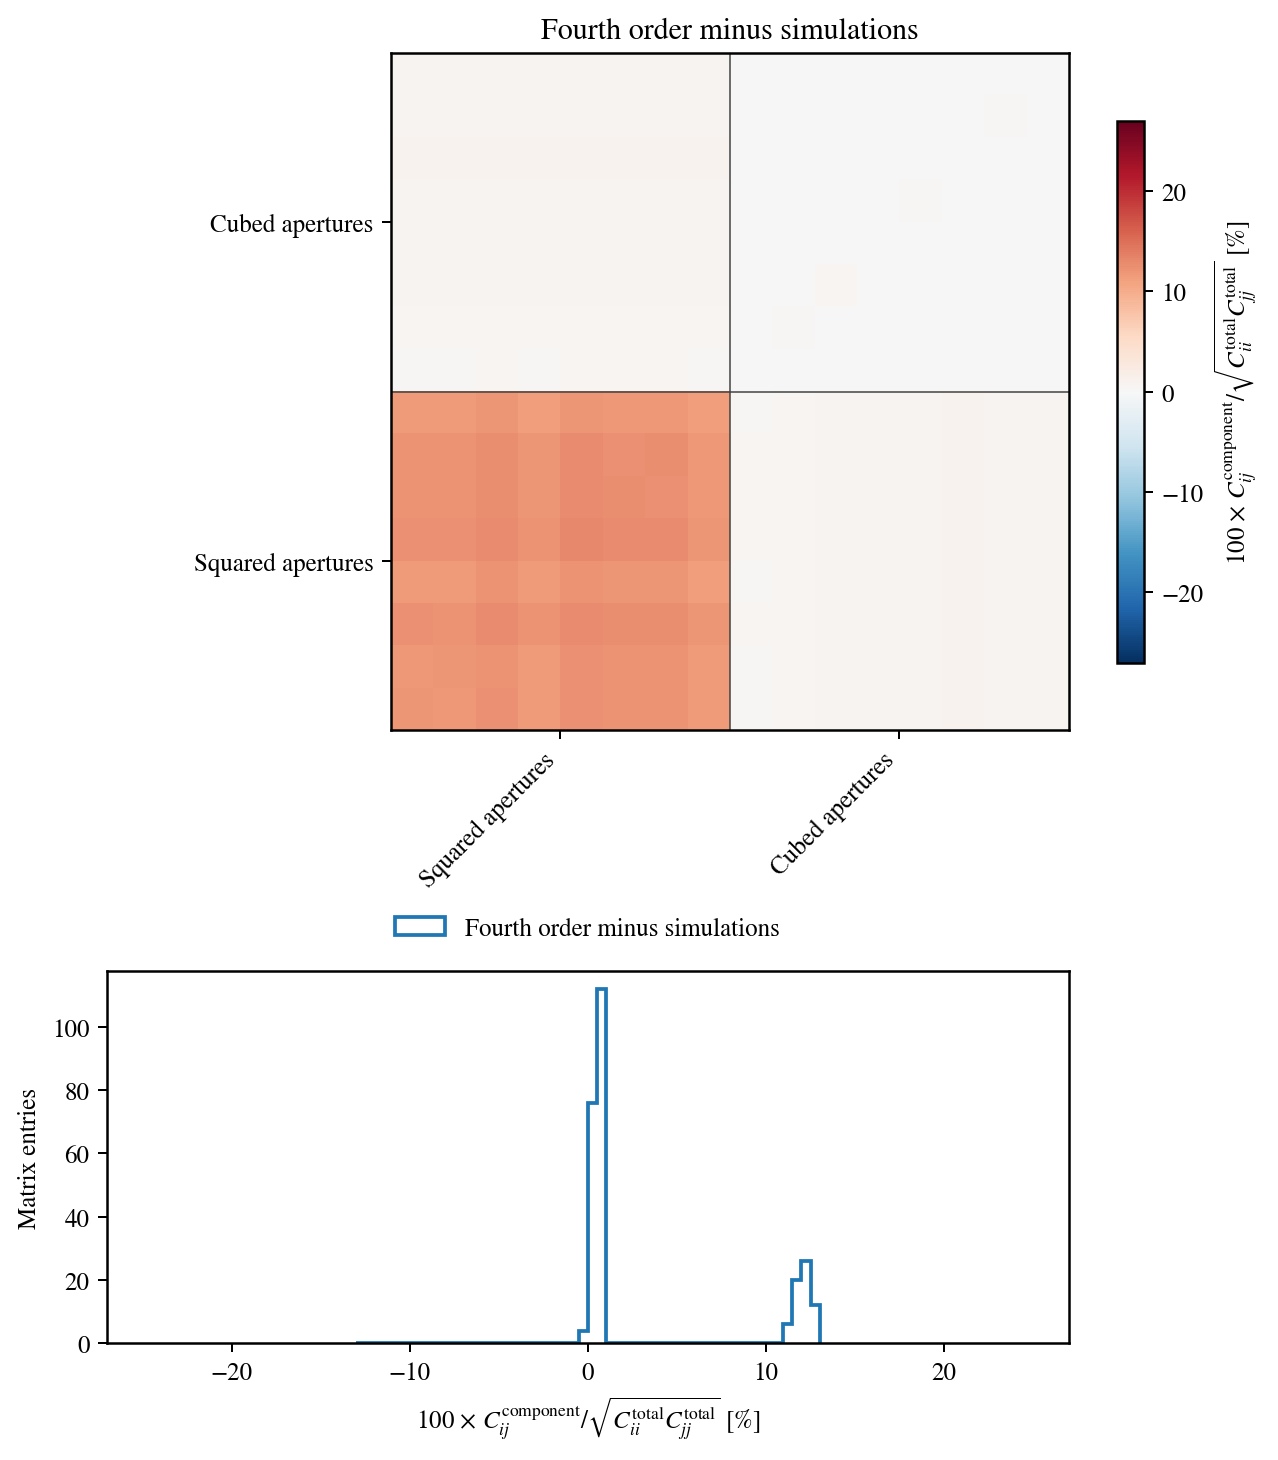

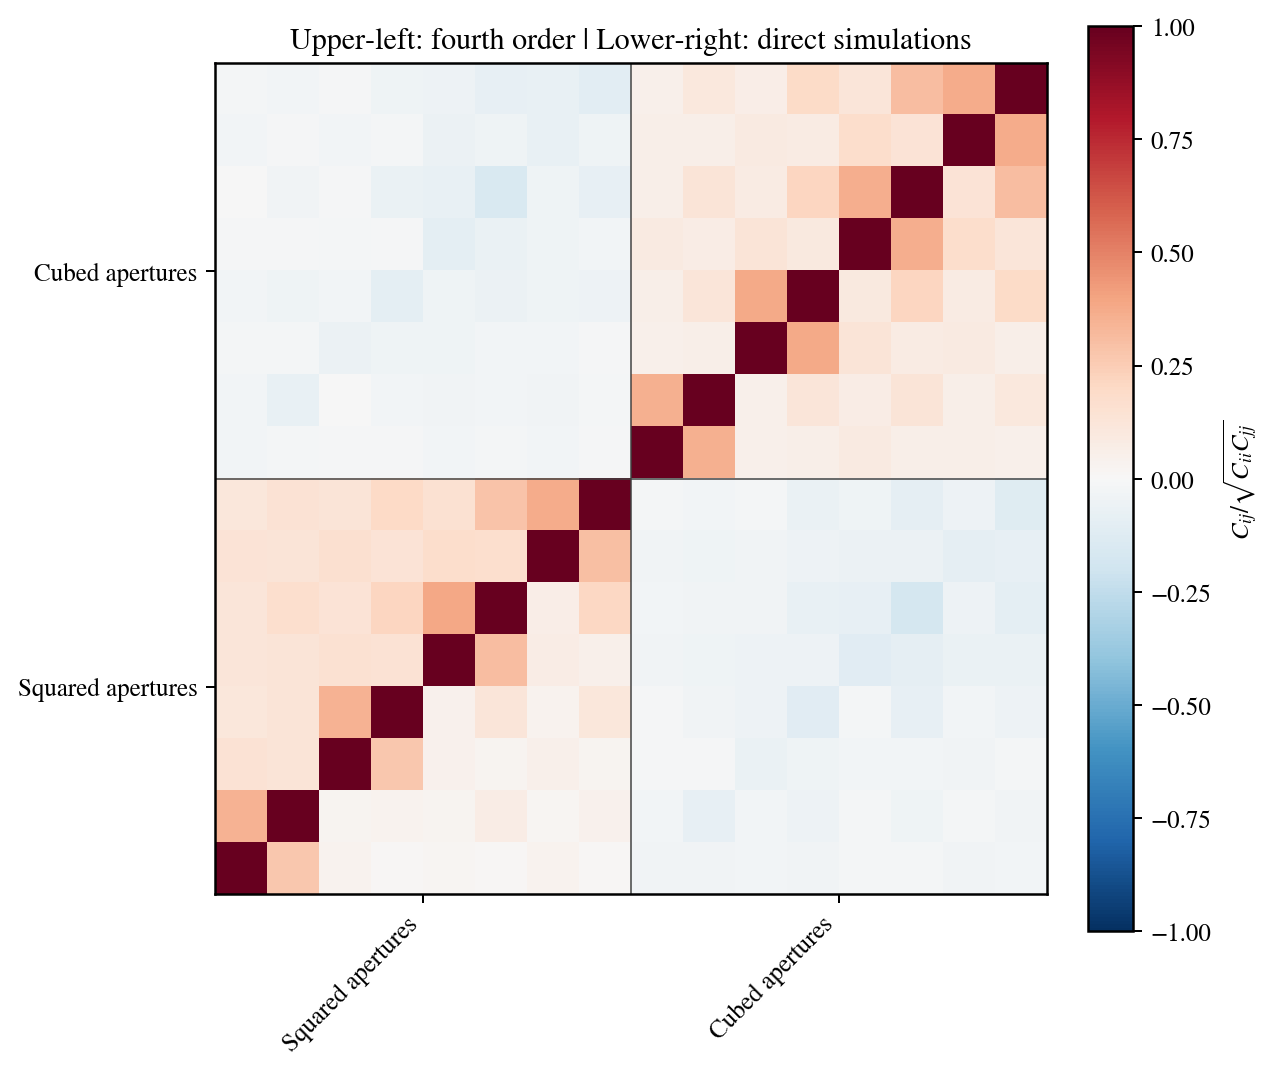

In [7]:
fig, axes = covplots.plot_covariance_components(
    total=all_covariance,
    components={"Fourth order minus simulations": fourth_covariance - all_covariance},
    block_sizes=[8, 8],
    block_labels=["Squared apertures", "Cubed apertures"],
    normalization="diagonal",
    percent=True,
    figsize=(7, 8),
    show=None,
)
axes["maps"][0].set_title(label="Fourth order minus simulations")
# Use the same color range for second and fourth order.
axes["maps"][0].images[0].set_clim(vmin=-27., vmax=27.)
axes["histogram"].set_xlim(left=-27., right=27.)
plt.show()
fig, ax = covplots.plot_correlation(
    covariance=fourth_covariance,
    covariance_ref=all_covariance,
    block_sizes=[8, 8],
    block_labels=["Squared apertures", "Cubed apertures"],
    labels=["Fourth order", "Direct simulations"],
    figsize=(7, 6),
    show=None,
)
ax.set_title(label="Upper-left: fourth order | Lower-right: direct simulations")
plt.show()

## 4. Why many simulations do not eliminate a second-order difference

Without the finite-$N$ square correction, the second-order polynomial is
$3I-3S+S^2$. Along an eigenvector of $S$ with eigenvalue $\lambda$, its
precision weight relative to the direct inverse is

$$\lambda(3-3\lambda+\lambda^2)=1+(\lambda-1)^3.$$

The smallest measured eigenvalue is about 0.168. This gives a weight near
0.424, or a covariance ratio near 2.36 along that combination of rows.
The infinite series can converge while its **second-order truncation** is
still inaccurate in a direction. More simulations reduce sampling noise;
they do not change that algebraic truncation at fixed $S$ and $M$.

The per-row standard deviations change by +10.8% to +12.5% for squared
moments and −0.12% to +1.44% for cubed moments. Correlation coefficients
change by as much as 0.199. In this nominal-count calculation, the
finite-$N$ square term changes standard deviations by only 0.029%–0.061%
relative to the uncorrected second-order polynomial. Most of the remaining
matrix difference is therefore the finite-order expansion, not that term.
This comparison does not identify either estimator with the unknown true
covariance.

In [8]:
# Isolate the finite-N arithmetic from truncation, keeping S and M fixed.
uncorrected_polynomial = 3. * np.eye(16) - 3. * all_whitened + all_square
left_restored = np.linalg.solve(a=all_factor.T, b=uncorrected_polynomial)
uncorrected_precision = np.linalg.solve(a=all_factor.T, b=left_restored.T).T
uncorrected_covariance = np.linalg.solve(a=uncorrected_precision, b=np.eye(16))
square_term_change = 100. * (
    np.sqrt(np.diag(all_eifler_covariance) / np.diag(uncorrected_covariance)) - 1.
)
print("Finite-N square correction: standard-deviation change [%]:", square_term_change)
minimum_sample_mode = np.linalg.eigvalsh(all_whitened)[0]
weight = 1. + (minimum_sample_mode - 1.)**3
print("Smallest sample eigenvalue:", minimum_sample_mode)
print("Uncorrected second-order weight along that mode:", weight)

Finite-N square correction: standard-deviation change [%]: [0.03227456 0.03517651 0.03113761 0.03441571 0.03224348 0.03414771
 0.02906752 0.04016002 0.04592529 0.03797185 0.02919412 0.04686196
 0.03441212 0.05428208 0.03964547 0.06090869]
Smallest sample eigenvalue: 0.16794588864498797
Uncorrected second-order weight along that mode: 0.42395725315562127


## 5. Use the released joint covariance as a comparison target

The project already contains Rafael's released 480-row covariance and its
paired measurements. Its rows are ordered as 200 xi-plus, 200 xi-minus, then
80 Map3 entries. The Map3 covariance block exactly matches the block in the
released Map3 measurement file. The standalone two-point covariance differs
from the joint file's two-point block; we therefore use the **joint file**
consistently for this comparison.

The joint FITS header records `NSIM=500`, while the selected upstream
analysis configuration and methods paper specify 796. These are conflicting
pieces of provenance. We record them and leave the input untouched. Do not
choose degrees of freedom for a covariance likelihood from that header
without resolving the conflict.

The released covariance is useful for checking the measurement's scale,
correlations, and row definitions. If it was estimated from the same parent
skies, agreement is **not independent validation**. Its own finite-sample
noise also remains. It cannot automatically become a noise-free reference
for the precision-expansion test.

In [9]:
from astropy.io import fits

released_data = PROJECT / "data" / "upstream_y3_observed" / "data"
joint_file = released_data / "covariance" / "xip_xim_map3_covariance_8ARCMINCUT_25Feb25.fits"
two_point_file = released_data / "dv" / "real_2pt_desy3_unblind_g2flip_matchElisa_2025Mar10.fits"
map3_file = released_data / "dv" / "real_map3_desy3_unblind_scalecut3pcf_796simcov_2025Mar11.fits"
with fits.open(name=joint_file, memmap=False) as hdus:
    released_covariance = np.array(hdus["COVMAT"].data)
    header_count = hdus["COVMAT"].header["NSIM"]
standalone_two_point = fits.getdata(filename=two_point_file, extname="COVMAT")
standalone_map3 = fits.getdata(filename=map3_file, extname="COVMAT")
print("Joint covariance shape:", released_covariance.shape)
print("FITS header NSIM:", header_count)
# Read the explicit override in the selected upstream configuration. This
# audit does not execute Cosmosis or resolve its other included parameters.
configuration = (PROJECT / "data" / "upstream_y3_observed" / "config"
                 / "unblind-metacal-796sims-february-Percival-2ptfix-3pcfsc"
                 / "unblind-metacal-shear-2pt-map3-NLA-all.ini")
configured_counts = []
for line in configuration.read_text().splitlines():
    stripped = line.strip()
    if stripped.startswith("covariance_realizations ="):
        configured_counts.append(int(stripped.split("=", 1)[1]))
assert len(configured_counts) == 1
print("Selected upstream configuration covariance_realizations:", configured_counts[0])
print("Map3 block is identical:",
      np.array_equal(released_covariance[400:, 400:], standalone_map3))
print("Standalone two-point block is identical:",
      np.array_equal(released_covariance[:400, :400], standalone_two_point))
standalone_ratio = np.diag(standalone_two_point) / np.diag(released_covariance)[:400]
print("Standalone/joint two-point variance ratio range:",
      np.min(a=standalone_ratio), np.max(a=standalone_ratio))

Joint covariance shape: (480, 480)
FITS header NSIM: 500
Selected upstream configuration covariance_realizations: 796
Map3 block is identical: True
Standalone two-point block is identical: False
Standalone/joint two-point variance ratio range: 0.8951201942964255 1.0915854485512557


## 6. Compare four actual xi-plus bins

The second measurement driver uses TreeCorr to count shear pairs in the
released angular bins for source-bin slot four. The selected joint rows are
192–195, spanning 39.622–99.527 arcminutes. Both pair-binning and shear-angle
approximation tolerances are zero. The first map also compares tree grouping
with brute-force pairs on a 2,048-pixel subset. This replaces an earlier
approximate-bin attempt whose numerical changes were too large for the
comparison.

Run the bounded measurement from Cocoa:

```bash
python projects/des_3pcf/scripts/measure_covariance_xip.py --runs 32
```

This optional driver requires TreeCorr 5.1.2, LSSTDESC.Coord 1.3.0 and
astropy-healpix. It uses three OpenMP workers, leaving one core for the map
stream, with BLAS at one. The notebook below only reads its small saved table.

TreeCorr's spherical shear basis points west/north. We use `flip_g2=True`
to implement the same east/north assumption as the coarse aperture pilot.
The first map also records the opposite sign; it does not select a preferred
convention by matching the covariance. All map pixels have equal weights,
which still needs comparison with the producer's weighting. These maps are
NSIDE 512; the methods paper describes 1024. Matching angular bin edges
therefore establishes only part of an estimator match.

For $N$ provisional parent surveys, subtract their mean and compute

$$\widehat C_{ij}=\frac{1}{N-1}\sum_s
 (d_{si}-\bar d_i)(d_{sj}-\bar d_j).$$

This estimates the fluctuations of **one survey**, which is what the
released covariance describes. Dividing it by $N$ would instead estimate
the covariance of the ensemble mean and would make the comparison wrong.

In [10]:
XIP_MEASUREMENT = MEASUREMENT
print((XIP_MEASUREMENT / "measurement.txt").read_text())
xip_table = np.loadtxt(fname=XIP_MEASUREMENT / "xip.txt", ndmin=2)
xip_rows = np.loadtxt(fname=XIP_MEASUREMENT / "rows.txt", ndmin=2)
# Only the declared east/north assumption enters the sample covariance.
# The alternate sign for the first map is a convention check, not a new sky.
xip_sample = xip_table[xip_table[:, 1] == 1., 2:]
xip_parents = xip_table[xip_table[:, 1] == 1., 0].astype(int)
assert np.unique(xip_parents).size == len(xip_parents)
indices = xip_rows[:, 0].astype(int)
np.testing.assert_array_equal(indices, np.arange(192, 196))
xip_reference = released_covariance[np.ix_(indices, indices)]
# Rows are surveys and columns are angular bins. Subtract each column's
# mean; residuals.T @ residuals sums the outer products of all surveys.
# Dividing by N-1 gives the covariance of ONE survey, not of its mean.
xip_mean = np.mean(a=xip_sample, axis=0)
residuals = xip_sample - xip_mean
xip_covariance = residuals.T @ residuals / (len(xip_sample) - 1)
np.testing.assert_allclose(
    xip_covariance,
    np.cov(m=xip_sample, rowvar=False, ddof=1),
    rtol=1.e-13,
    atol=0.,
)
variance_ratio = np.diag(xip_covariance) / np.diag(xip_reference)
xip_mean = np.mean(a=xip_sample, axis=0)
mean_standard_error = np.sqrt(np.diag(xip_covariance) / len(xip_sample))
print("Measured primary run labels:", xip_parents)
print("Mean xi-plus:", xip_mean)
print("Standard error of that mean:", mean_standard_error)
print("One-survey variance / released variance:", variance_ratio)
# Correlation differences remain in the matrix; the diagonal ratio alone
# cannot establish equality of the two covariance matrices.
xip_factor = np.linalg.cholesky(xip_reference)
# If C_ref = L L^T, solve on the left and then on the right to form
# L^-1 C_sample L^-T. Triangular solves avoid explicitly forming L^-1.
left_solved = np.linalg.solve(a=xip_factor, b=xip_covariance)
xip_whitened = np.linalg.solve(a=xip_factor, b=left_solved.T).T
print("Covariance eigenvalues in released-model units:",
      np.linalg.eigvalsh(xip_whitened))
for flip in (0, 1):
    check = np.loadtxt(fname=XIP_MEASUREMENT / f"tree_check_flip{flip}.txt")
    print("Sign check", flip, "max tree/brute xi difference:",
          np.max(a=np.abs(check[:, 0] - check[:, 1])))

Parents: 32
Cut: 0
Draw: 0
Source-bin slot: 4
TreeCorr version: 5.1.2
OpenMP: 3
BLAS: 1
Weights: equal per retained pixel; producer weights unavailable
Tree approximations: bin_slop=0 angle_slop=0; 2048-pixel tree/brute check
Metric: Arc
NSIDE: 512
Pixel ordering: RING inferred from footprint
Signs: first map both signs; main sample flip_g2=True (assumed east/north)
Bins: released xi-plus rows 192..195, 39.622..99.527 arcmin
No catalogue-noise covariance from TreeCorr is used
Released matrix may share parent simulations; this is a consistency check
Cross tests: 8 same-run draw pairs and disjoint different-run pairs
Elapsed seconds: 502.265

Measured primary run labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31]
Mean xi-plus: [7.16869147e-06 5.79657858e-06 4.43694802e-06 3.05194156e-06]
Standard error of that mean: [1.96757673e-07 1.86474479e-07 1.48359059e-07 1.05140586e-07]
One-survey variance / released variance: [1.40577469 1.8

### A four-number jackknife example before the DES error bars

A jackknife asks how sensitive an estimate is to the observed runs. It
recomputes that estimate after omitting one run at a time. It does not
create new independent simulations and does not require a held-out group.
The reported covariance still uses every run.

Try four scalar measurements: $0,1,2,3$. Their ordinary sample variance is
$5/3$. Compare it with a fixed reference variance of $2$: the ratio is
$5/6$. Delete each observation and recompute the variance of the remaining
three numbers, dividing by **two**, not three. The four variance ratios are

$$\left(\frac12,\frac76,\frac76,\frac12\right).$$

Their average is $5/6$. The deviations from that average are

$$\left(-\frac13,\frac13,\frac13,-\frac13\right).$$

The jackknife variance estimate is the sum of squared deviations multiplied
by $(N-1)/N$:

$$V_{\rm jack}=\frac34\left(4\times\frac19\right)=\frac13.$$

Its standard error is $1/\sqrt3$. This four-number example teaches the
arithmetic; such a tiny sample does not guarantee well-calibrated error bars.
The notes derive the prefactor with pseudovalues and explain why the
leave-one-out results cannot be treated as independent experiments.

For a general statistic, define pseudovalues

$$p_s=N\widehat\theta-(N-1)\widehat\theta_{(-s)}.$$

For the sample mean, this returns observation $s$ exactly. Applying the
variance-of-a-mean expression to the pseudovalues and substituting
$p_s-\bar p=-(N-1)(\widehat\theta_{(-s)}-\bar\theta_{\rm delete})$
gives the jackknife prefactor $(N-1)/N$. For nonlinear statistics this
provides an approximate error estimate, not independent new observations.


In [11]:
jack_values = np.array([0., 1., 2., 3.])
jack_reference = 2.
jack_full = np.var(a=jack_values, ddof=1) / jack_reference
jack_ratios = []
for omitted in range(len(jack_values)):
    retained = np.delete(arr=jack_values, obj=omitted)
    # ddof=1 automatically changes the denominator to N-2 after deletion.
    ratio = np.var(a=retained, ddof=1) / jack_reference
    jack_ratios.append(ratio)
jack_ratios = np.array(jack_ratios)
jack_center = np.mean(a=jack_ratios)
jack_variance = (len(jack_values) - 1.) / len(jack_values) * np.sum(
    (jack_ratios - jack_center)**2,
)
np.testing.assert_allclose(jack_ratios, [0.5, 7./6., 7./6., 0.5])
np.testing.assert_allclose(jack_variance, 1./3.)
# Pseudovalues make the same variance formula look like variance-of-a-mean.
# For nonlinear statistics they are not independent new data points.
jack_pseudovalues = len(jack_values) * jack_full - (len(jack_values) - 1) * jack_ratios
np.testing.assert_allclose(
    np.var(a=jack_pseudovalues, ddof=1) / len(jack_values),
    jack_variance,
)
print("Full-sample variance ratio:", jack_full)
print("Leave-one-out ratios:", jack_ratios)
print("Jackknife standard error:", np.sqrt(jack_variance))

Full-sample variance ratio: 0.8333333333333334
Leave-one-out ratios: [0.5        1.16666667 1.16666667 0.5       ]
Jackknife standard error: 0.5773502691896258


The bars below measure sensitivity to leaving out one parent at a time.
They describe uncertainty in our small measured sample; they omit noise in
the released reference and any dependence from shared parent skies. The
line at one marks equal variances for a single survey. A disagreement calls
for checks of resolution, weights, shear conventions, and simulation
content before interpreting it as a failure of covariance physics.

Even agreement would establish consistency for four two-point rows only.
The Map3 and cross-covariance blocks still require the published triangle
measurement and scale cuts. No precision correction or Fisher constraint is
computed from this comparison.

If $r_i^{(-s)}$ is the ratio after removing run $s$, first average those
leave-one-out ratios to obtain $\bar r_i^{\rm jack}$. Their scatter gives

$$\widehat{\mathrm{Var}}_{\rm jack}(r_i)=\frac{N-1}{N}
\sum_s(r_i^{(-s)}-\bar r_i^{\rm jack})^2.$$

The plotted bar is the square root of this quantity. Each leave-one-out
sample shares almost all its maps with the others; the prefactor accounts
for that reuse in the jackknife estimate. It is not the ordinary variance
of 32 independent estimates.

Variance-ratio jackknife standard errors: [0.3723697  0.42048988 0.44524493 0.28075769]


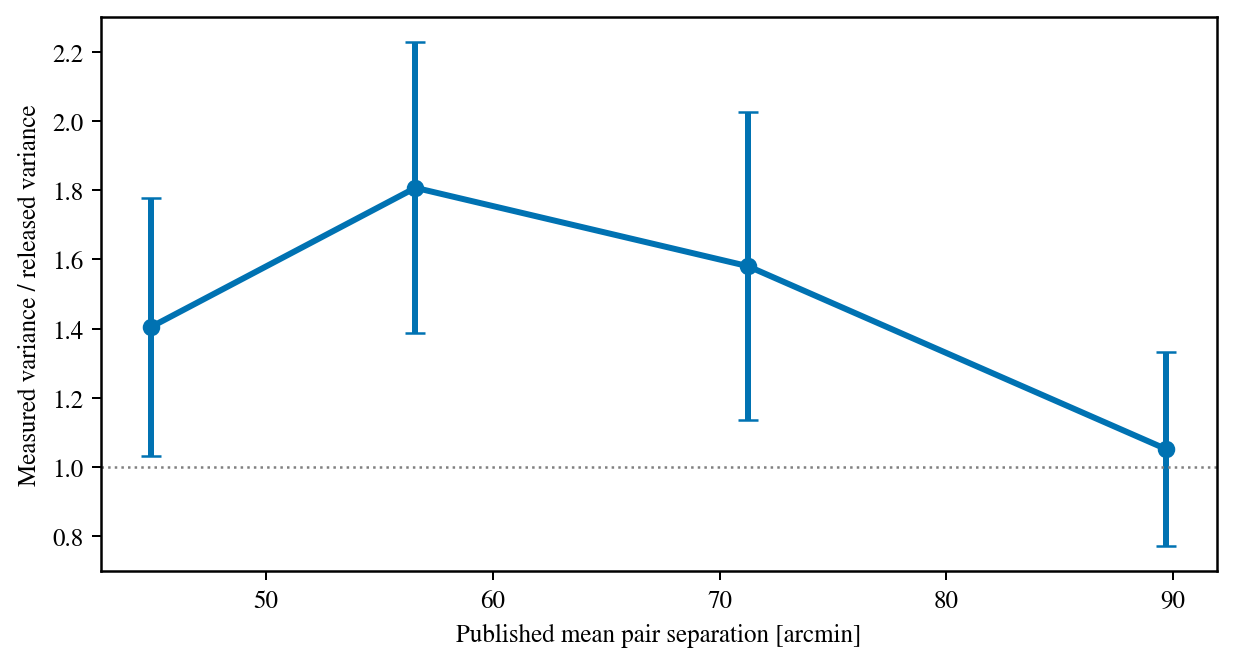

In [12]:
# These small jackknife calculations reuse the measured vectors only.
leave_one_out = []
for omitted in range(len(xip_sample)):
    selection = np.arange(len(xip_sample)) != omitted
    covariance = np.cov(m=xip_sample[selection], rowvar=False, ddof=1)
    leave_one_out.append(np.diag(covariance) / np.diag(xip_reference))
leave_one_out = np.asarray(leave_one_out)
centered = leave_one_out - np.mean(a=leave_one_out, axis=0)
count = len(xip_sample)
ratio_standard_error = np.sqrt((count - 1.) / count * np.sum(a=centered**2, axis=0))
print("Variance-ratio jackknife standard errors:", ratio_standard_error)
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(x=xip_rows[:, 3], y=variance_ratio, yerr=ratio_standard_error,
            color="#0072B2", marker="o", linewidth=2.4, capsize=4)
ax.axhline(y=1., color="0.5", linestyle=":", linewidth=1.)
ax.set_xlabel("Published mean pair separation [arcmin]")
ax.set_ylabel("Measured variance / released variance")
plt.show()

## 7. Compare measured and released DES matrices in the same two ways

These four xi-plus rows have matching angular-bin definitions. They are a
different statistic from the sixteen aperture moments above; their matrices
must not be compared entry by entry with those sixteen-row matrices.
Here the difference normalization uses the released DES diagonal. The upper-left
triangle shows the measured correlation and the lower-right shows the release.
The 32-run sampling uncertainty, equal pixel weights, pixel resolution and
unconfirmed shear conventions remain relevant to interpreting differences.

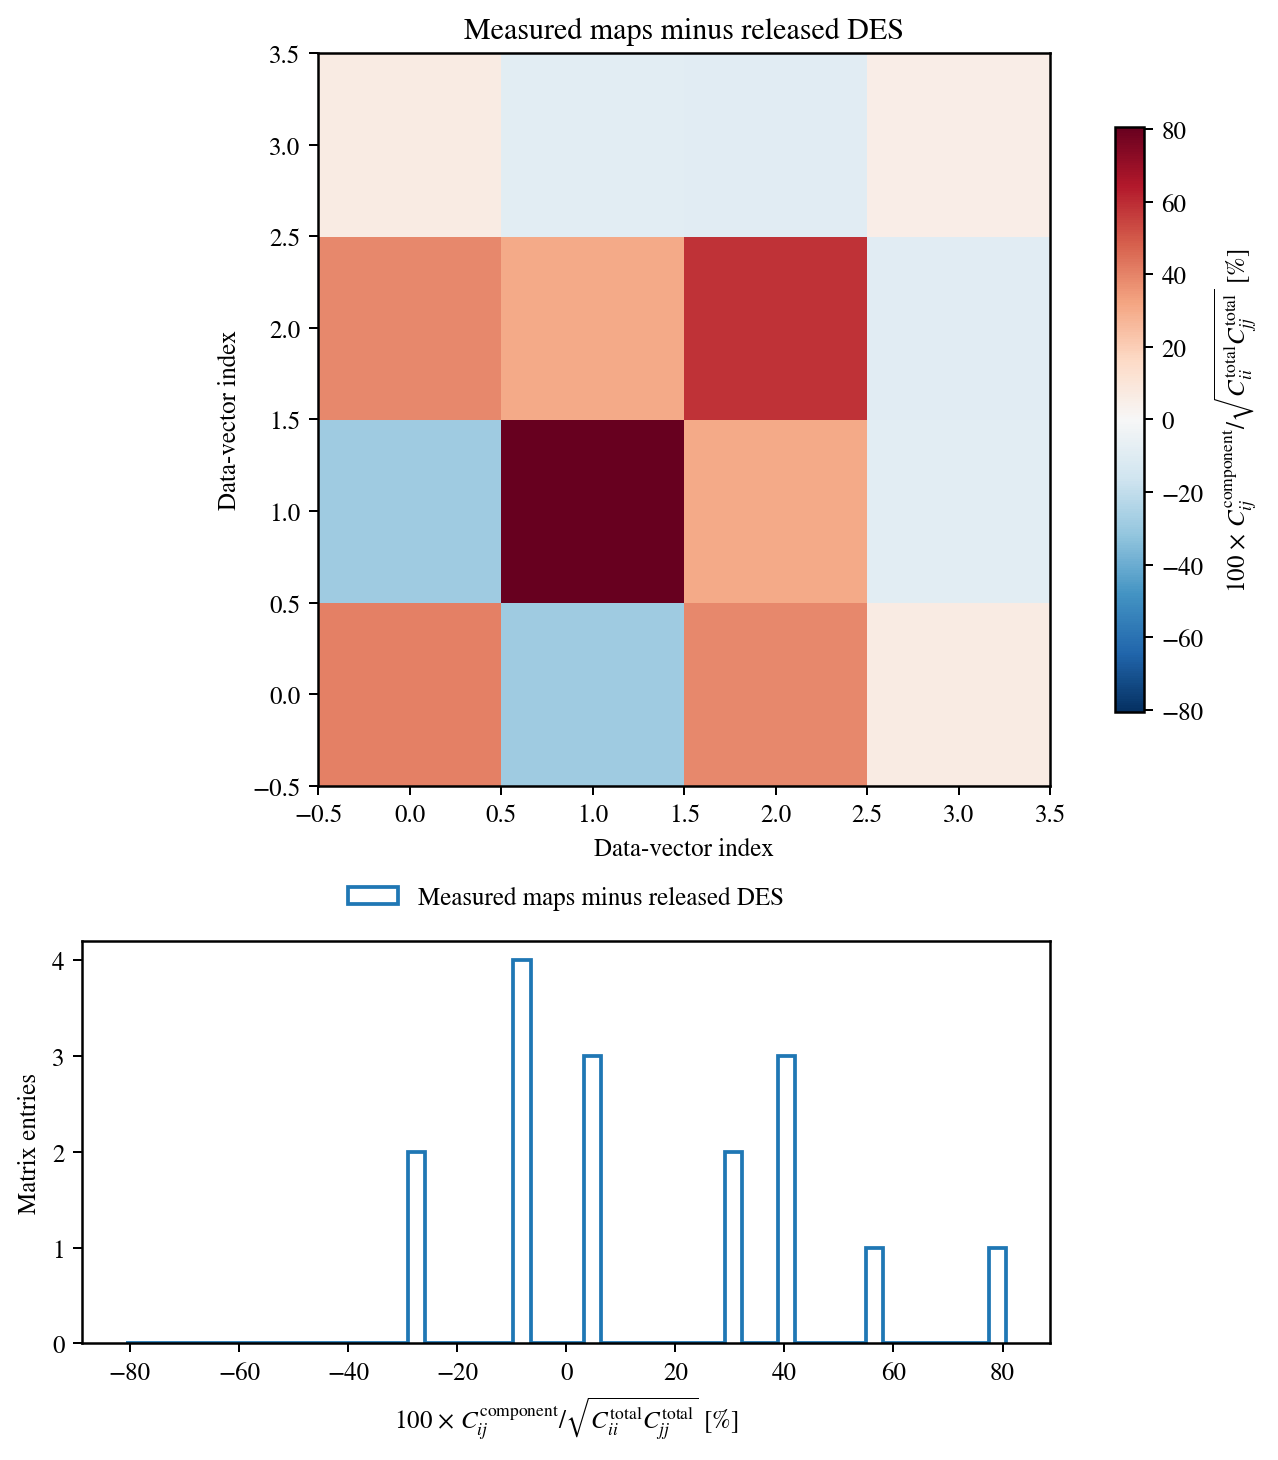

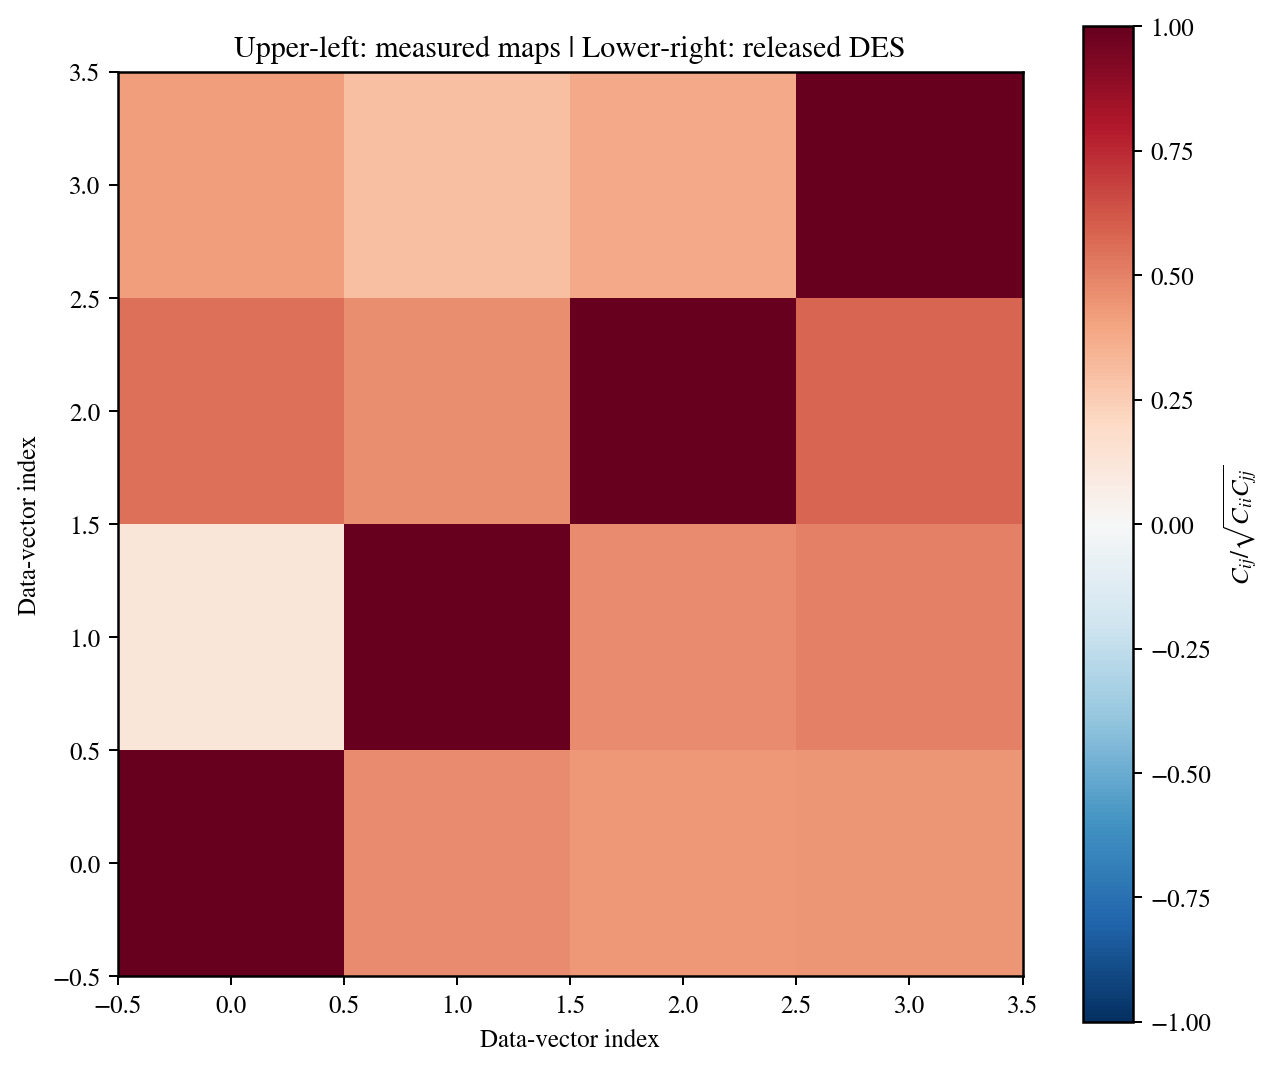

In [13]:
fig, axes = covplots.plot_covariance_components(
    total=xip_reference,
    components={"Measured maps minus released DES": xip_covariance - xip_reference},
    normalization="diagonal",
    percent=True,
    figsize=(7, 8),
    show=None,
)
axes["maps"][0].set_title(label="Measured maps minus released DES")
fig.canvas.draw()
legend = axes["histogram"].get_legend()
assert legend.get_window_extent().y0 > axes["histogram"].get_window_extent().y1
plt.show()
fig, ax = covplots.plot_correlation(
    covariance=xip_covariance,
    covariance_ref=xip_reference,
    labels=["Measured maps", "Released DES"],
    figsize=(7, 6),
    show=None,
)
ax.set_title(label="Upper-left: measured maps | Lower-right: released DES")
plt.show()


## 8. Record the numerical and shear-convention checks separately

The tree/direct-pair test compares the *same* 2,048 pixels with the same
spin-two convention. Agreement tests the pair-counting calculation. It does
not identify which convention the map producer intended. The first primary
map was measured with both signs of its second shear component; the following
cell reports that difference in units of the released single-survey error.
A small difference is not permission to leave the convention undefined.
The pair driver uses zero angular-bin and shear-angle approximation tolerances;
none of TreeCorr's estimated shot-noise errors enters our covariance.

Two additional controls check the cross-correlation route itself. Cross-correlating
two distinct catalogue objects containing the *same map* must recover its
auto-correlation. A second check compares the cross-correlation of two
*different maps* with direct pair enumeration on the same 2,048-pixel subset.
Together they test normalization and pair processing before interpreting
an observed cross signal near zero.

In [14]:
# Both rows refer to the SAME sky: they must never count as two surveys.
first_run = xip_table[:, 0] == 0
sign_rows = xip_table[first_run]
assert np.array_equal(sign_rows[:, 1], np.array([0., 1.]))
sign_difference = sign_rows[1, 2:] - sign_rows[0, 2:]
released_errors = np.sqrt(np.diag(xip_reference))
print("Changing flip_g2, difference / released single-survey error:",
      sign_difference / released_errors)
for flip in (0, 1):
    check = np.loadtxt(fname=MEASUREMENT / f"tree_check_flip{flip}.txt")
    assert np.all(check[:, 2] > 0)
    np.testing.assert_allclose(check[:, 0], check[:, 1], rtol=0., atol=1.e-16)
    print("Sign", flip, "direct-pair subset check passed; pair counts:", check[:, 2])
# This positive control must retain a signal: distinct catalogue objects
# carrying identical shear fields should give the usual auto-correlation.
for filename in ("self_cross_check.txt", "cross_tree_check.txt"):
    check = np.loadtxt(fname=MEASUREMENT / filename)
    np.testing.assert_allclose(check[:, 0], check[:, 1], rtol=0., atol=1.e-16)
    print(filename, "maximum difference:", np.max(a=np.abs(check[:, 0] - check[:, 1])))

Changing flip_g2, difference / released single-survey error: [-0.03151488 -0.0382525   0.01814052  0.02726496]
Sign 0 direct-pair subset check passed; pair counts: [ 336.  510.  830. 1346.]
Sign 1 direct-pair subset check passed; pair counts: [ 336.  510.  830. 1346.]
self_cross_check.txt maximum difference: 1.929541053845296e-18
cross_tree_check.txt maximum difference: 0.0


## 9. Reproduction record

The all-file covariance is a recorded sufficient input for the matrix
comparison. `RECOMPUTE_ALL_COVARIANCE` verifies it against all 15,997 saved
moment vectors when that local table is available. No simulation map is
reread by this check. `RUN_MEASUREMENT` repeats the separate bounded xi-plus
measurement using the existing project driver and optional TreeCorr stack.

No rows or simulations are reserved for validation in either comparison.
The all-file PME uses the stated nominal count; the DES comparison uses all
32 measured xi-plus vectors. The note and plots retain those two different
sample sizes and measurement definitions. Neither comparison supplies a
validated production DES covariance or an independently tested precision.

## Extension: the same complete sample at sixth order

The source `sixth_order_comparison.py` solves the exact Gaussian moment equations and uses the same 15,997-vector covariance, reference matrix and nominal count. The full algebra belongs in the separate teaching note. No split sample or refit enters here.

The weakest relative precision weight is still only about 0.724 at sixth order. Its approach toward the direct inverse does not establish Gaussianity, file independence or physical accuracy. The two figures retain the same display conventions as the lower orders.

[[2.         0.10772065 0.12534366 0.19906333 0.42393138 0.95834509]
 [4.         0.0547435  0.06315093 0.1089026  0.60107137 0.97357991]
 [6.         0.03206459 0.03697076 0.06578081 0.72364633 0.98169915]]
Nominal Gaussian count only; neither independence nor exact truth established.


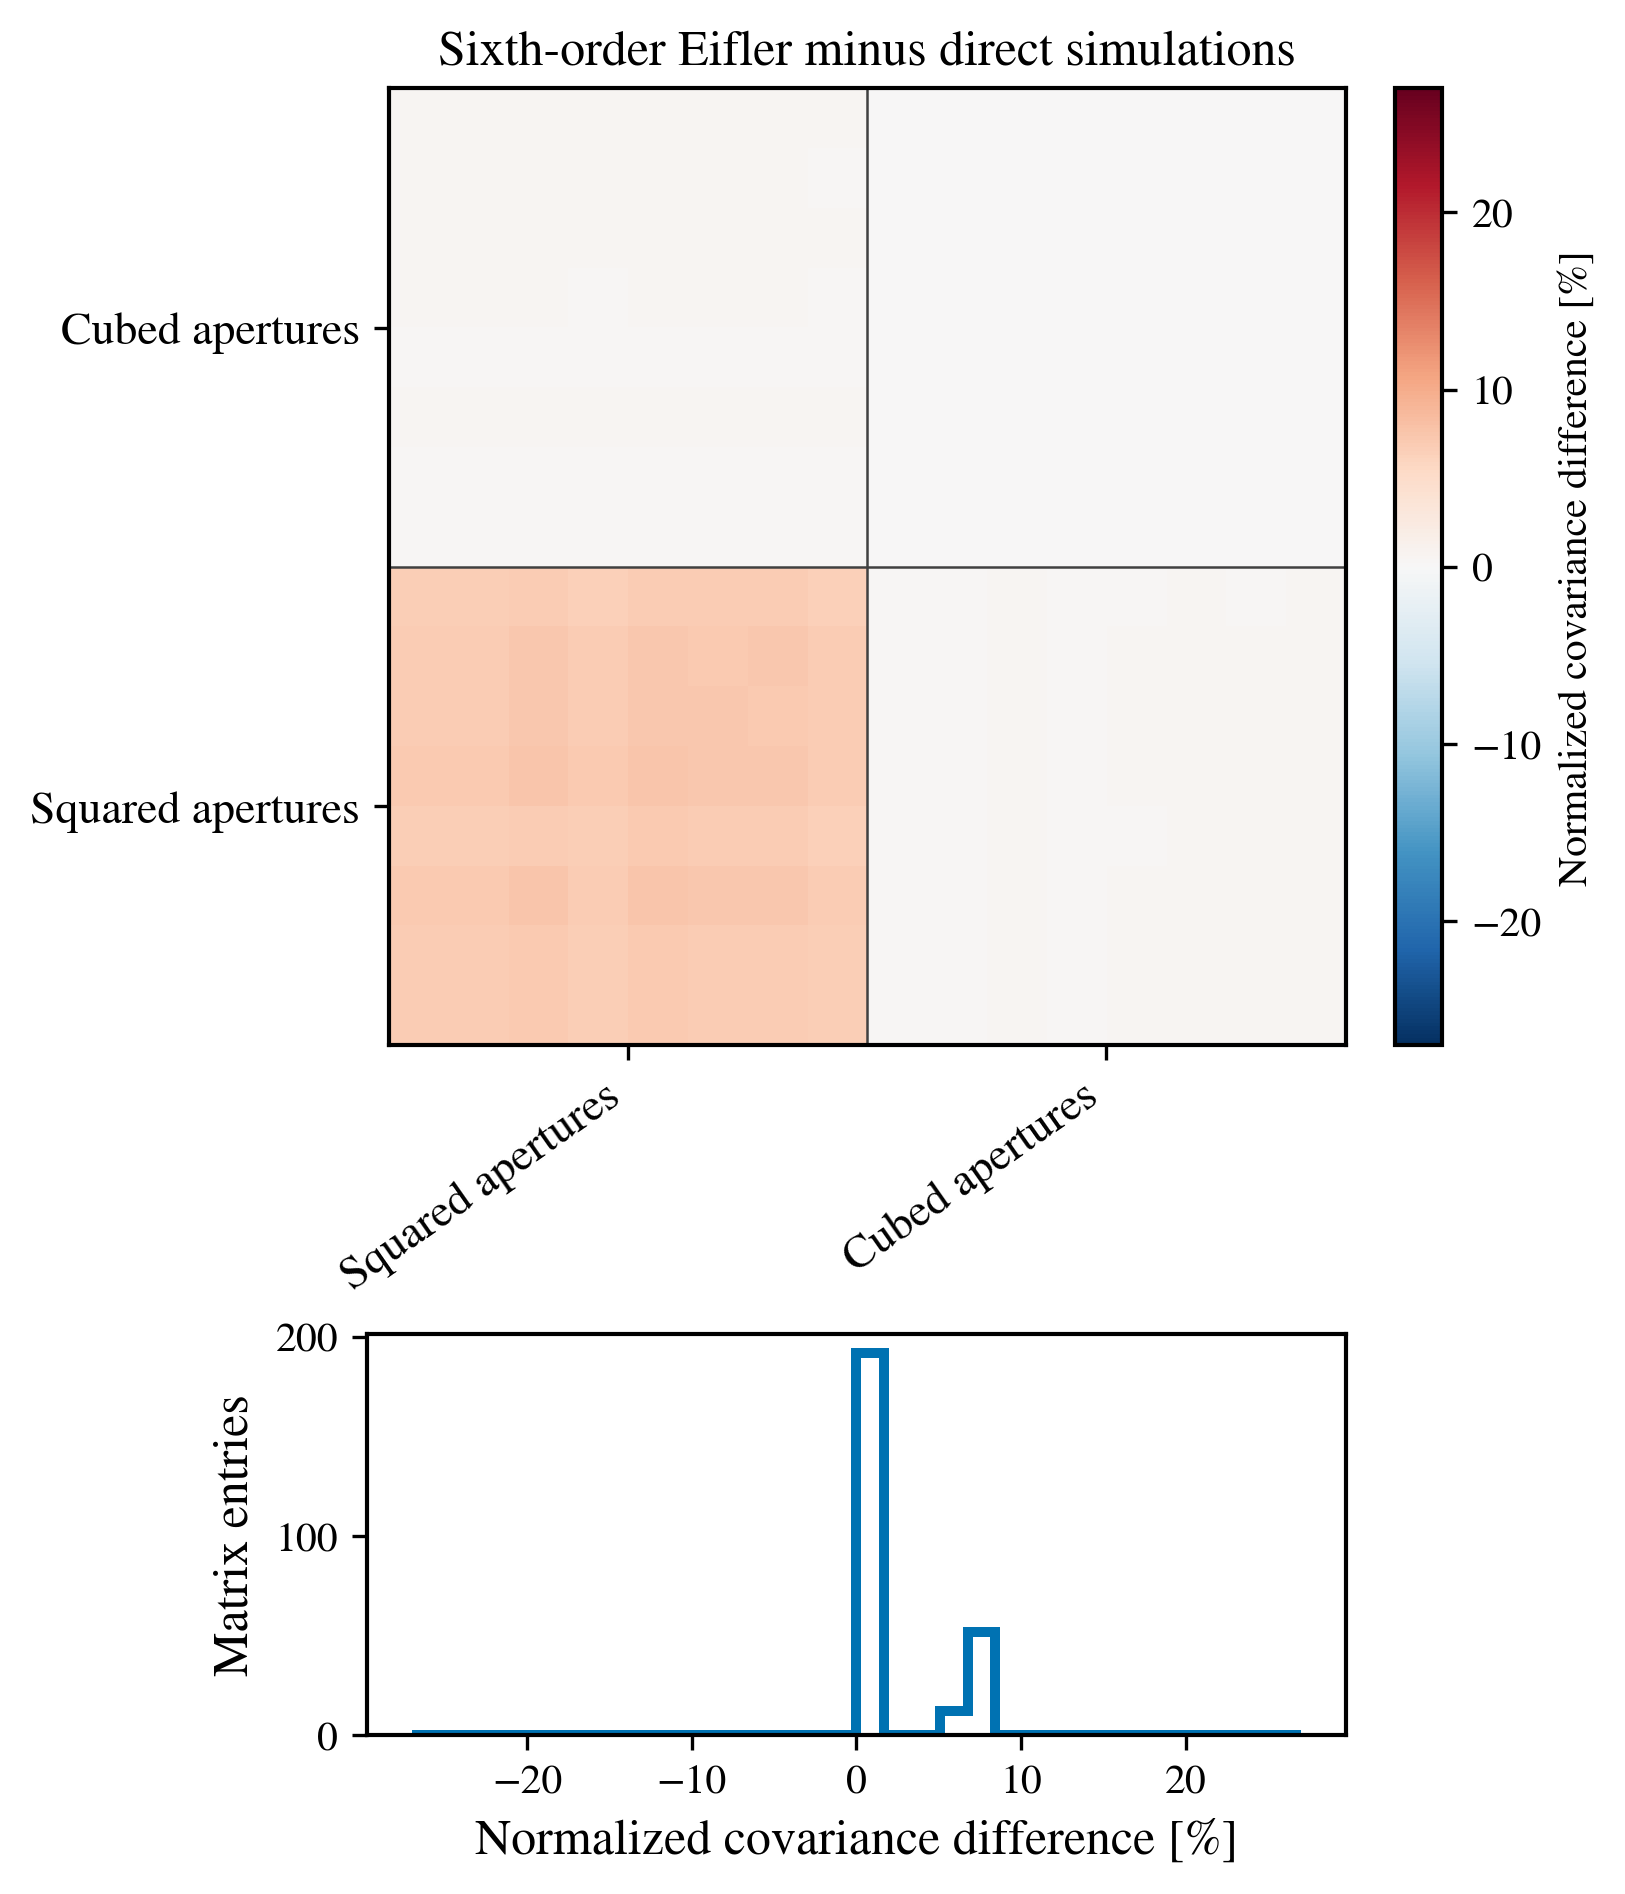

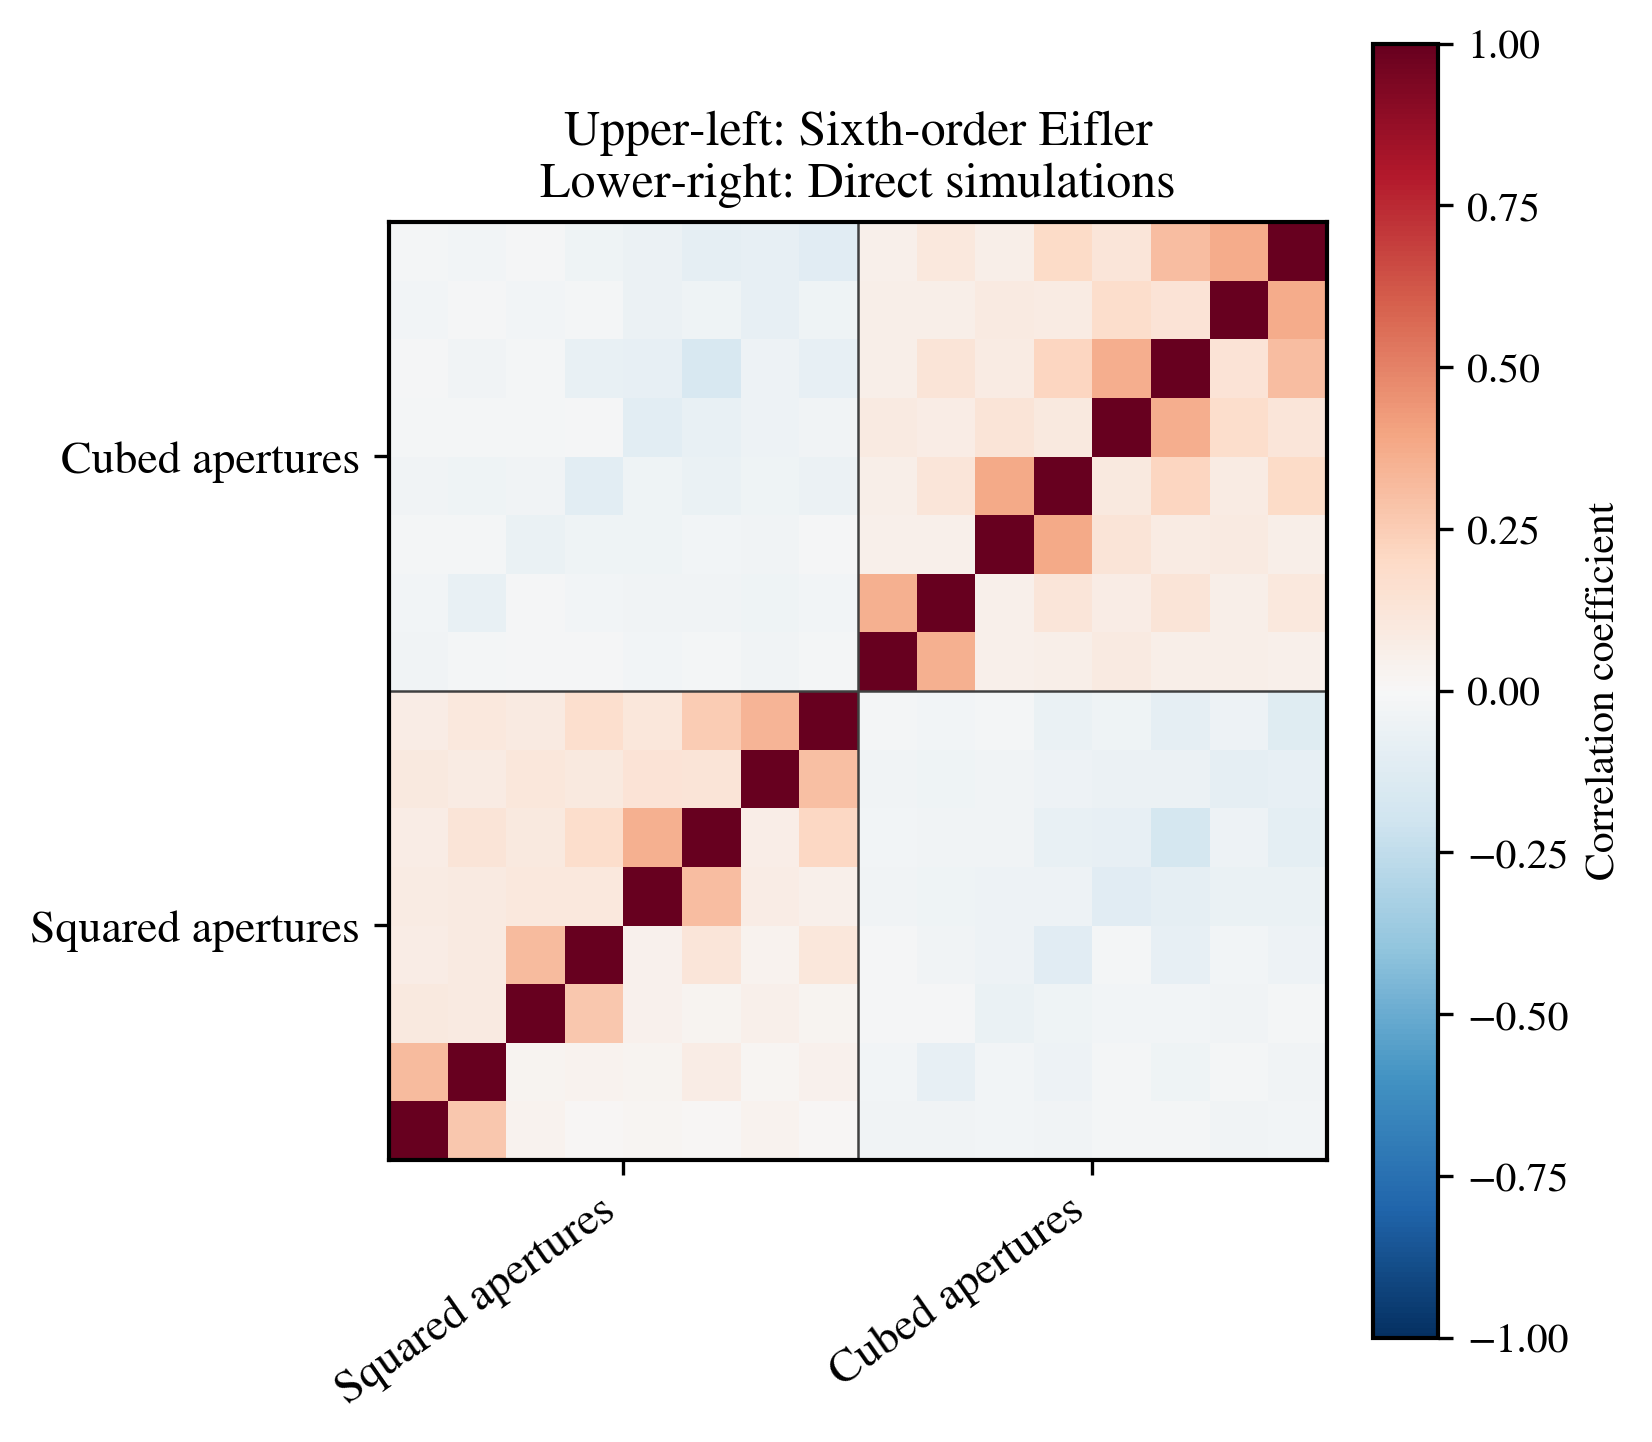

In [15]:
# Repeat the numerical extension from the compact complete-sample covariance.
# This reads no raw maps. Exact symbolic coefficients take several seconds.
import runpy
import sys
precision_path = PROJECT / 'notes' / 'covariance_from_simulations'
if str(precision_path) not in sys.path:
    sys.path.insert(0, str(precision_path))
extension = runpy.run_path(
    path_name=str(PROJECT / 'notes/covariance_comparison/sixth_order_comparison.py'),
)
extension['main']()
from IPython.display import Image, display
for figure in ('sixth_difference', 'sixth_triangles'):
    display(Image(
        filename=str(PROJECT / 'notes/covariance_comparison/plots'
                     / figure / f'{figure}.png'),
        width=650,
    ))

## Is the direct inverse stable enough to be truth?

We have not established that. A bounded diagnostic deletes all cuts and draws belonging to one run label while keeping the comparison direction fixed. The full estimate still uses all files. There are 200 labels with 77–80 files each; treating them as independent parent groups is provisional, and the equal-group jackknife prefactor is approximate for these slightly unequal sizes.

The direction was selected from the full-sample sixth-order comparison. Its deletion scatter is descriptive, not an independent confidence test. The nested prefixes below share data and end at one by construction. The separate GPTG study uses newly generated validation maps to score precision estimates without identifying the direct inverse as truth.

`check_sample_inverse.py` repeats the diagnostic from the complete saved moment table under `chains/covariance_maps_full/`; the default notebook reads its compact recorded results.

In [16]:
# Compact deletion records retain run labels and group sizes, making the
# grouping assumption visible without reopening any map array.
deletions = np.loadtxt(
    fname=PROJECT / 'tests/covariance_map_comparison/direct_inverse_deletions.txt',
)
weights = deletions[:, 2]
groups = len(weights)
jackknife_se = np.sqrt((groups-1)/groups * np.sum((weights-weights.mean())**2))
print('Run groups and size range:', groups, deletions[:,1].min(), deletions[:,1].max())
print('Direct weight after one whole-group deletion:', weights.min(), weights.max())
print('Approximate group-jackknife relative SE:', jackknife_se)
growth = np.loadtxt(
    fname=PROJECT / 'tests/covariance_map_comparison/direct_inverse_growth.txt',
)
print('Nested group count, vector count, weight relative to all groups:')
print(growth)
print('This is stability in one data-selected direction, not proof of survey truth.')

Run groups and size range: 200 77.0 80.0
Direct weight after one whole-group deletion: 0.9981574633754593 1.0033042471483011
Approximate group-jackknife relative SE: 0.01382487208775888
Nested group count, vector count, weight relative to all groups:
[[2.50000000e+01 2.00000000e+03 1.04243303e+00]
 [5.00000000e+01 4.00000000e+03 9.78383349e-01]
 [1.00000000e+02 8.00000000e+03 9.96181599e-01]
 [1.50000000e+02 1.19970000e+04 9.99374887e-01]
 [2.00000000e+02 1.59970000e+04 1.00000000e+00]]
This is stability in one data-selected direction, not proof of survey truth.
